# 5.7 Statistical Tests

**Goal:** select and apply eleven common tests while checking design, estimand, and distributional assumptions.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Sampling Techniques](1_Sampling-Techniques.ipynb)
2. [Sampling Concepts](2_Sampling-Concepts.ipynb)
3. [Estimation Theory](3_Estimation-Theory.ipynb)
4. [Confidence Intervals](4_Confidence-Intervals.ipynb)
5. [Hypothesis Testing](5_Hypothesis-Testing.ipynb)
6. [Statistical Errors](6_Statistical-Errors.ipynb)
7. [Statistical Tests](7_Statistical-Tests.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Z-test and One-sample T-test

A one-sample **z-test** for a mean uses known population σ and statistic $(\bar x-\mu_0)/(\sigma/\sqrt n)$. The exact reference is normal for normal independent observations; CLT-based versions are approximations. A one-sample **t-test** replaces σ with s and uses tₙ₋₁ under IID normal sampling. The target is a population mean, not a median or normality itself.

**Example:** compare eight measurements with a reference mean 10. A t-test is appropriate only if the sample/design supports the mean comparison; software does not check independence.

In [2]:
x=np.array([9.,10.,12.,11.,14.,13.,8.,12.])
z=(x.mean()-10)/(3/np.sqrt(len(x)))
print("Known sigma=3 z and p:",z,2*stats.norm.sf(abs(z)))
print("One-sample t:",stats.ttest_1samp(x,popmean=10))

Known sigma=3 z and p: 1.0606601717798214 0.2888443663464849
One-sample t: TtestResult(statistic=np.float64(1.5666989036012806), pvalue=np.float64(0.16116849528146354), df=np.int64(7))


## 2. Independent T-test and Paired T-test

Independent samples require independent groups and units within groups. **Welch's t-test** tests equal means without equal population variances, using $(\bar x-\bar y)/\sqrt{s_x²/n_x+s_y²/n_y}$ and Welch–Satterthwaite degrees of freedom. Student's pooled t-test additionally assumes equal variance. Do not pool by default merely because group sizes match.

A **paired t-test** applies a one-sample t-test to within-pair differences, assuming independent pairs and a normal difference distribution for exact small-sample inference. Pairing is a design property (same user, matched unit), not a consequence of equal array lengths. Independent and paired tests answer different sampling questions.

In [3]:
a=np.array([10.,12.,9.,15.,11.,13.]);b=np.array([11.,13.,11.,17.,12.,16.])
print("Welch independent:",stats.ttest_ind(a,b,equal_var=False))
print("Paired b-a:",stats.ttest_rel(b,a))
assert np.isclose(stats.ttest_rel(b,a).statistic,stats.ttest_1samp(b-a,0).statistic)

Welch independent: TtestResult(statistic=np.float64(-1.2126781251816656), pvalue=np.float64(0.25396565879442035), df=np.float64(9.697986577181208))
Paired b-a: TtestResult(statistic=np.float64(5.000000000000001), pvalue=np.float64(0.004104715980053318), df=np.int64(5))


## 3. One-way ANOVA

Classical one-way ANOVA tests equality of k independent group means under independent normal errors with common variance. $F=MS_{between}/MS_{within}$ has degrees of freedom k−1 and N−k under H₀. An omnibus rejection means not all means are equal; it does not identify which pair differs. Use planned contrasts or multiplicity-adjusted post-hoc analyses. Robust or Welch variants address unequal variances under their own assumptions.

**Example:** compare three independently randomized treatments. Histograms of outcomes do not establish residual independence; experimental design supplies that assumption.

In [4]:
groups=[np.array([9,10,11,12,10.]),np.array([12,13,14,12,15.]),np.array([10,11,10,12,11.])]
print("One-way ANOVA:",stats.f_oneway(*groups))

One-way ANOVA: F_onewayResult(statistic=np.float64(9.297297297297295), pvalue=np.float64(0.0036409881005157))


## 4. Two-way ANOVA

A factorial model with two factors includes main effects and potentially an interaction: $Y_{ijk}=\mu+\alpha_i+\beta_j+(\alpha\beta)_{ij}+\epsilon_{ijk}$. An interaction means the effect of one factor depends on the level of the other. Interpret main effects cautiously when interactions are material.

The following **balanced replicated design** has a levels, b levels, and r observations per cell. With independent common-variance normal errors, test each term using its mean square over residual mean square. Degrees of freedom are a−1, b−1, (a−1)(b−1), and ab(r−1). Unbalanced designs require careful model/contrast definitions and sums-of-squares choices; this simple decomposition should not be blindly reused there.

A F: 27.0 p: 0.0008262751659886822
B F: 48.0 p: 0.00012104020555530016
A:B F: 12.0 p: 0.008516263370901282


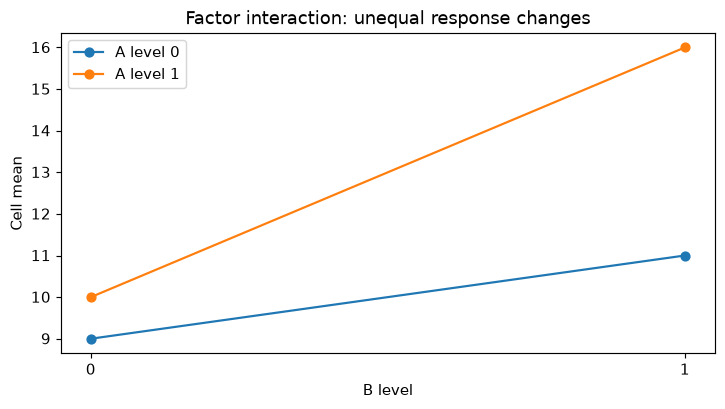

In [5]:
# Shape: factor A levels, factor B levels, independent within-cell replicates.
y=np.array([[[8.,9.,10.],[10.,11.,12.]],[[9.,10.,11.],[15.,16.,17.]]])
a_levels,b_levels,r=y.shape;grand=y.mean();cell=y.mean(axis=2)
mean_a=y.mean(axis=(1,2));mean_b=y.mean(axis=(0,2))
ss_a=b_levels*r*np.sum((mean_a-grand)**2)
ss_b=a_levels*r*np.sum((mean_b-grand)**2)
ss_ab=r*np.sum((cell-mean_a[:,None]-mean_b[None,:]+grand)**2)
ss_error=np.sum((y-cell[:,:,None])**2);df_error=a_levels*b_levels*(r-1)
for name,ss,df in [("A",ss_a,a_levels-1),("B",ss_b,b_levels-1),("A:B",ss_ab,(a_levels-1)*(b_levels-1))]:
    F=(ss/df)/(ss_error/df_error)
    print(name,"F:",F,"p:",stats.f.sf(F,df,df_error))
assert np.isclose(ss_a+ss_b+ss_ab+ss_error,np.sum((y-grand)**2))
fig,ax=plt.subplots()
for i in range(a_levels):ax.plot(range(b_levels),cell[i],marker="o",label=f"A level {i}")
ax.set(title="Factor interaction: unequal response changes",xlabel="B level",ylabel="Cell mean",xticks=[0,1]);ax.legend()
fig.tight_layout();plt.show()

## 5. Chi-square Test and Fisher's Exact Test

The **chi-square independence test** compares observed contingency counts with expected counts $E_{ij}=row_i\,total\times column_j\,total/N$. Statistic $\sum(O-E)^2/E$ has asymptotic χ² degrees of freedom (r−1)(c−1) under appropriate independent sampling. Sparse expected counts can undermine the approximation; the common “at least five” rule is a heuristic, not a universal theorem. A chi-square goodness-of-fit test instead compares one categorical distribution with prespecified probabilities, adjusting df when parameters were estimated.

For a 2×2 table, **Fisher's exact test** uses a conditional hypergeometric null with fixed margins. It avoids a large-sample chi-square approximation but remains dependent on design and a specified alternative. Report an effect measure such as an odds ratio with suitable uncertainty, not only p. Paired binary outcomes need a matched test such as McNemar's, not ordinary independence tests.

In [6]:
table=np.array([[12,8],[5,15]])
chi=stats.chi2_contingency(table,correction=False)
print("Chi-square statistic/p:",chi.statistic,chi.pvalue,"expected:\n",chi.expected_freq)
print("Fisher 2x2:",stats.fisher_exact(table,alternative="two-sided"))
print("Goodness of fit to equal probabilities:",stats.chisquare([18,22,20],f_exp=[20,20,20]))

Chi-square statistic/p: 5.012787723785166 0.025160759200408736 expected:
 [[ 8.5 11.5]
 [ 8.5 11.5]]
Fisher 2x2: SignificanceResult(statistic=np.float64(4.5), pvalue=np.float64(0.05355099259437413))
Goodness of fit to equal probabilities: Power_divergenceResult(statistic=np.float64(0.4), pvalue=np.float64(0.8187307530779818))


## 6. Mann–Whitney U Test

Mann–Whitney compares two **independent** samples using pooled ranks. Its usual null calibration assumes equal distributions/exchangeability; under a common-shape location-shift model it can be interpreted as a location comparison. It is not a universal test of medians when spreads or shapes differ. The U statistic also estimates $P(X>Y)+\tfrac12P(X=Y)$ through normalization, with orientation stated.

Ties and small samples affect exact versus asymptotic methods. The [SciPy reference](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html) explains the alternative and method choices. Rank methods still require an appropriate independent design.

In [7]:
u=stats.mannwhitneyu(a,b,alternative="two-sided",method="asymptotic")
print("Mann-Whitney:",u,"estimated P(a>b)+half ties:",u.statistic/(len(a)*len(b)))

Mann-Whitney: MannwhitneyuResult(statistic=np.float64(11.0), pvalue=np.float64(0.29283365264601635)) estimated P(a>b)+half ties: 0.3055555555555556


## 7. Wilcoxon Signed-Rank Test and Kruskal–Wallis Test

The **Wilcoxon signed-rank test** uses independent paired differences, ranking their absolute magnitudes and restoring signs. Its location interpretation assumes a symmetric continuous difference distribution around the tested value. It is not assumption-free and is not interchangeable with an independent rank-sum test. Zero differences and ties need an explicit handling/method choice; rounding artifacts can create false distinct ranks. See the [signed-rank documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html).

**Kruskal–Wallis** extends pooled-rank comparison to multiple independent groups. Its standard null is equal distributions; a median/location interpretation needs similarly shaped group distributions. H has an asymptotic χ²ₖ₋₁ reference, with tie correction. Rejection is omnibus, not a list of differing pairs; small/sparse groups can need a suitable permutation alternative. The [SciPy implementation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kruskal.html) supplies the rank statistic and asymptotic p-value.

In [8]:
differences=np.array([1.,2.,3.,4.,5.,6.])
print("Wilcoxon unique nonzero differences:",stats.wilcoxon(differences,alternative="two-sided",method="exact"))
print("Kruskal-Wallis:",stats.kruskal(*groups))

Wilcoxon unique nonzero differences: WilcoxonResult(statistic=np.float64(0.0), pvalue=np.float64(0.03125))
Kruskal-Wallis: KruskalResult(statistic=np.float64(8.478358208955225), pvalue=np.float64(0.014419423826491407))


## 8. Test-selection guide

| Design and target | Candidate | Important condition |
|---|---|---|
| One numerical mean, known σ | Z | Valid normal/large-sample reference |
| One mean, unknown σ | One-sample t | Normality for small-sample exactness |
| Two independent means | Welch t | Independent units, suitable mean SE |
| Paired mean difference | Paired t | Independent pairs, difference assumptions |
| Multiple independent means | One-way ANOVA | Classical common-error variance |
| Two crossed factors | Two-way ANOVA | Interaction and replication modeled |
| Categorical count association | Chi-square / Fisher | Unpaired independent observations |
| Two independent rank distributions | Mann–Whitney | Null exchangeability, shape for location claims |
| Paired symmetric differences | Wilcoxon | Pairing and symmetry |
| Multiple independent rank distributions | Kruskal–Wallis | Omnibus; shape for median claims |

Choosing a test by a normality-test p-value alone is not a sound decision rule. Consider estimand, design, robustness, sample size, ties, missingness, and the entire analysis pipeline.

## AI/ML application and interpretation

Use these tests for model comparisons, experiment analysis, A/B testing, and statistical validation only when the unit/design matches the inference. Cross-validation folds overlap in training data, so a naive independent-fold t-test can be optimistic. Report estimated improvement, uncertainty, practical relevance, and multiplicity alongside any rejection decision.

## Practice

1. Two models predict on exactly the same test users. Should their per-user losses be analyzed as independent groups?
2. Does an ANOVA rejection identify the best-performing group?
3. Why include an interaction in a two-factor experiment?
4. Does Mann–Whitney always test equal medians?
5. What distribution must be symmetric for a usual signed-rank location interpretation?
6. Why can a chi-square independence test be wrong for repeated outcomes from the same users?

## Solutions

1. Usually not: preserve paired users and analyze paired loss differences with an appropriate method. Retraining/fold dependence adds further issues.
2. No. It says at least one mean differs under the model; follow-up comparisons require planned or adjusted inference.
3. The effect of one factor can depend on the other. Omitting a real interaction can hide or distort that pattern.
4. No. A median/location interpretation needs additional distribution-shape assumptions; equal medians can coexist with different rank distributions.
5. The within-pair difference distribution around its null center, with independent pairs.
6. The standard test assumes independent sampling units. Repeated user records create dependence that affects uncertainty and reference calibration.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](../6-Correlation-Covariance-and-Regression/1_Correlation.ipynb).